<sub>**The Annotated ML Handbook** · Part VI: TensorFlow & Keras</sub>

# Chapter 27: Neural networks with Keras

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-6-tensorflow-keras/27-keras-mlp.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 27.1 The Keras workflow in five steps · *Beginner*

**1–2: data and model definition**

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(0)
X, y = load_breast_cancer(return_X_y=True)
X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.2, stratify=y_tmp, random_state=0)
scaler = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = [scaler.transform(a).astype("float32") for a in (X_tr, X_va, X_te)]
print(X_tr.shape, X_va.shape, X_te.shape)

model = keras.Sequential([
    keras.Input(shape=(X_tr.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.summary()

I0000 00:00:1795690919.514820    6330 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795690920.626877    6330 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


(364, 30) (91, 30) (114, 30)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

**3–5: compile, fit, evaluate**

In [3]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
history = model.fit(X_tr, y_tr,
                    validation_data=(X_va, y_va),
                    epochs=200, batch_size=32, verbose=0)
test_loss, test_acc, test_auc = model.evaluate(X_te, y_te, verbose=0)
print(f"test loss={test_loss:.4f} accuracy={test_acc:.4f} AUC={test_auc:.4f}")
proba = model.predict(X_te[:5], verbose=0).ravel()
print("probabilities:", proba.round(3), "-> labels:", (proba >= 0.5).astype(int))

test loss=0.2592 accuracy=0.9561 AUC=0.9625
probabilities: [0. 0. 0. 1. 0.] -> labels: [0 0 0 1 0]


**Plot the training history**

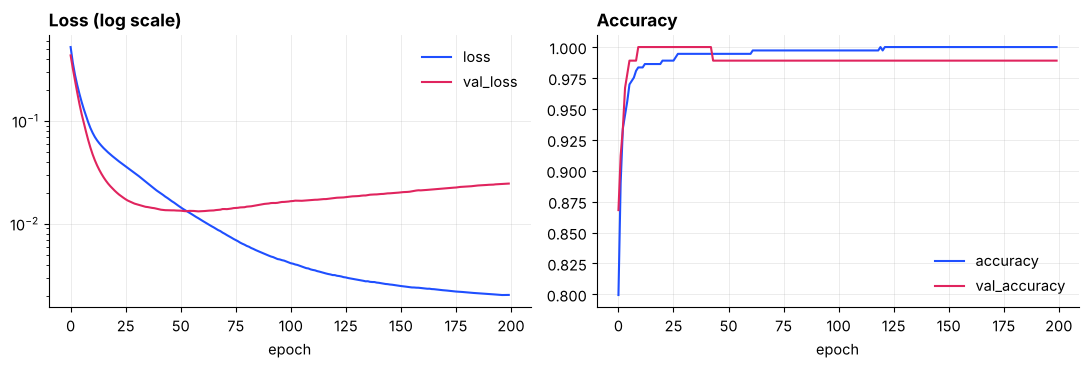

epoch with lowest val_loss: 59


In [4]:
h = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
h[["loss", "val_loss"]].plot(ax=axes[0], title="Loss (log scale)", logy=True)
h[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Accuracy")
for ax in axes: ax.set_xlabel("epoch")
plt.tight_layout()
plt.show()
print("epoch with lowest val_loss:", int(h["val_loss"].idxmin()) + 1)

## 27.2 Choosing the output layer and loss · *Beginner*

## 27.3 Callbacks: early stopping, checkpoints, learning-rate schedules · *Intermediate*

**Stop when validation loss stops improving**

In [5]:
keras.utils.set_random_seed(0)
def build_model(units=32, dropout=0.0, l2=0.0):
    reg = keras.regularizers.l2(l2) if l2 else None
    m = keras.Sequential([
        keras.Input(shape=(X_tr.shape[1],)),
        layers.Dense(units, activation="relu", kernel_regularizer=reg),
        layers.Dropout(dropout),
        layers.Dense(units // 2, activation="relu", kernel_regularizer=reg),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return m

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint("best_mlp.keras", monitor="val_loss", save_best_only=True),
]
m = build_model(dropout=0.3, l2=1e-3)
hist = m.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=300, batch_size=32, callbacks=callbacks, verbose=0)
print("stopped after", len(hist.history["loss"]), "epochs")
print("test accuracy:", round(m.evaluate(X_te, y_te, verbose=0)[1], 4))

stopped after 61 epochs
test accuracy: 0.9649


### 27.3.1 Regularisation compared · *Intermediate*

**Dropout and L2 reduce the train–validation gap**

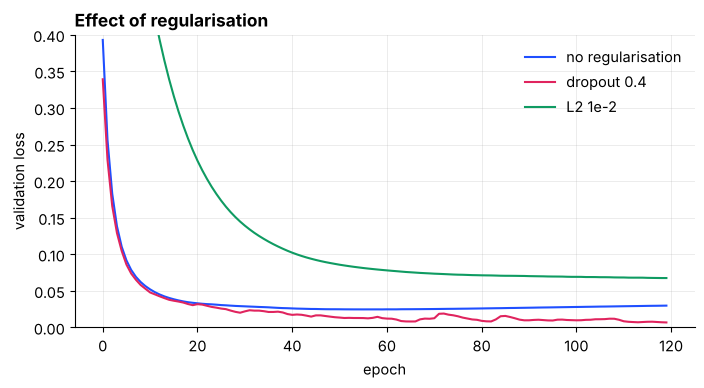

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for label, kw in [("no regularisation", {}), ("dropout 0.4", {"dropout": 0.4}), ("L2 1e-2", {"l2": 1e-2})]:
    keras.utils.set_random_seed(1)
    hh = build_model(units=64, **kw).fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=120, batch_size=32, verbose=0)
    ax.plot(hh.history["val_loss"], label=label)
ax.set(xlabel="epoch", ylabel="validation loss", title="Effect of regularisation", ylim=(0, 0.4))
ax.legend()
plt.show()

## 27.4 Multiclass classification · *Intermediate*

**Wine cultivars with softmax**

In [7]:
from sklearn.datasets import load_wine
Xw, yw = load_wine(return_X_y=True)
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.25, stratify=yw, random_state=0)
sc = StandardScaler().fit(Xw_tr)
Xw_tr, Xw_te = sc.transform(Xw_tr).astype("float32"), sc.transform(Xw_te).astype("float32")

keras.utils.set_random_seed(0)
mc = keras.Sequential([keras.Input(shape=(13,)),
                       layers.Dense(32, activation="relu"),
                       layers.Dense(3, activation="softmax")])
mc.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mc.fit(Xw_tr, yw_tr, epochs=80, batch_size=16, validation_split=0.2, verbose=0)
probs = mc.predict(Xw_te, verbose=0)
print(probs[:3].round(3), probs[:3].sum(axis=1))
print("test accuracy:", round(float(np.mean(probs.argmax(axis=1) == yw_te)), 4))

[[0.001 0.001 0.998]
 [0.659 0.336 0.005]
 [0.    0.998 0.001]] [1.        0.9999999 1.       ]
test accuracy: 1.0


## 27.5 Regression · *Intermediate*

**Predicting insurance charges with an MLP**

In [8]:
ins = pd.read_csv("insurance.csv").dropna()
Xi = pd.get_dummies(ins.drop(columns="charges"), drop_first=True, dtype=float)
yi = ins["charges"].to_numpy(dtype="float32") / 1000
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.2, random_state=0)
sci = StandardScaler().fit(Xi_tr)
Xi_tr, Xi_te = sci.transform(Xi_tr).astype("float32"), sci.transform(Xi_te).astype("float32")

keras.utils.set_random_seed(0)
reg = keras.Sequential([keras.Input(shape=(Xi_tr.shape[1],)),
                        layers.Dense(64, activation="relu"),
                        layers.Dense(32, activation="relu"),
                        layers.Dense(1)])
reg.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
reg.fit(Xi_tr, yi_tr, validation_split=0.2, epochs=400, batch_size=32, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(patience=25, restore_best_weights=True)])
mse, mae = reg.evaluate(Xi_te, yi_te, verbose=0)
print(f"test RMSE = {np.sqrt(mse) * 1000:,.0f}   MAE = {mae * 1000:,.0f}  (charges)")

test RMSE = 1,997   MAE = 1,603  (charges)


## 27.6 The Functional API · *Advanced*

**Two inputs, one output, with a skip connection**

In [9]:
num_in = keras.Input(shape=(5,), name="numeric")
cat_in = keras.Input(shape=(1,), name="category", dtype="int32")
emb = layers.Flatten()(layers.Embedding(input_dim=10, output_dim=4)(cat_in))
h = layers.Dense(16, activation="relu")(num_in)
h = layers.Concatenate()([h, emb, num_in])
out = layers.Dense(1, activation="sigmoid", name="prob")(h)
fm = keras.Model(inputs=[num_in, cat_in], outputs=out)
fm.compile(optimizer="adam", loss="binary_crossentropy")
rng = np.random.default_rng(0)
fm.fit({"numeric": rng.normal(size=(64, 5)).astype("float32"), "category": rng.integers(0, 10, (64, 1))},
       rng.integers(0, 2, 64), epochs=2, verbose=0)
print([t.name for t in fm.inputs], fm.output_shape, fm.count_params())

['numeric', 'category'] (None, 1) 162


## 27.7 Saving and loading · *Beginner*

**The native .keras format**

In [10]:
m.save("cancer_mlp.keras")
restored = keras.models.load_model("cancer_mlp.keras")
print(np.allclose(restored.predict(X_te, verbose=0), m.predict(X_te, verbose=0)))
m.save_weights("cancer_mlp.weights.h5")

True


## Try it yourself

1. Replace the two hidden layers with one layer of 8 units. Does test accuracy change? What about 256 units?
2. Add `layers.BatchNormalization()` after each Dense layer and compare the training curves.
3. Wrap `build_model` in a loop over five seeds and report test accuracy as mean ± SD.

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 27*.